# Veri Dönüşümü ve Dengeleme: Encoding, Ölçekleme, Feature Engineering ve SMOTE

**Proje:** Framingham Kalp Çalışması verisi ile inme (stroke) tahmini

**Girdi:** Kişi 1'in `01_veri_onisleme` notebook'unda hazırladığı `train.csv` ve `test.csv`. Bu dosyalarda sızıntılı sütunlar çıkarılmış, imkânsız değerler temizlenmiş ve eksik değerler (yalnızca eğitim verisinin istatistikleriyle) doldurulmuştur.

**Bu notebook'ta yapılanlar:**
1. Encoding: sayıya çevrilmesi gereken sütunlar
2. Ölçekleme (standardizasyon)
3. Feature engineering: tıbben anlamlı yeni özellikler
4. Adımların veri üzerindeki etkisi
5. Veri dengeleme: SMOTE
6. Ekibin ortak kullanacağı Pipeline

Adımların kodu ekibin ortak kullandığı **`src/onisleme_pipeline.py`** dosyasındadır.

**Colab'da çalıştırmak için:** Sol menüdeki klasör simgesinden `train.csv`, `test.csv` (Kişi 1'in çıktıları) ve `onisleme_pipeline.py` dosyalarını yükleyin.

```
Kişi 1'in verisi → ① feature engineering → ② encoding + ölçekleme → ③ dengeleme (SMOTE) → ④ model
```

> **Veri sızıntısı önlemi:** Tüm adımlar tek bir Pipeline içinde olduğu için ölçekleme parametreleri ve SMOTE yalnızca **eğitim verisinden** öğrenilir. Cross validation sırasında her katta yalnızca o katın eğitim kısmına uygulanır. Test seti bu notebook'ta kullanılmaz.

In [1]:
# Colab'da imbalanced-learn hazır gelir; yerelde yoksa: %pip install -q imbalanced-learn
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

def bul(dosya, klasorler):
    """Dosyayı repo yapısında (../data, ../src) veya Colab'da (çalışma klasörü) arar."""
    for k in klasorler:
        if (Path(k) / dosya).exists():
            return Path(k)
    raise FileNotFoundError(f"{dosya} bulunamadı. Colab'da sol menüden yükleyin.")

sys.path.insert(0, str(bul("onisleme_pipeline.py", ["../src", "src", "."])))
VERI = bul("train.csv", ["../data", "data", "."])

import pandas as pd
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from onisleme_pipeline import (FeatureEngineer, build_preprocessor, build_pipeline,
                               veriyi_ayir, RANDOM_STATE)

pd.set_option("display.max_columns", None)

# Kişi 1'in hazırladığı eğitim/test verisi (yeni bir bölme yapılmaz)
X_train, X_test, y_train, y_test = veriyi_ayir(pd.read_csv(VERI / "train.csv"), pd.read_csv(VERI / "test.csv"))
print("Eğitim verisi:", X_train.shape, "| inme oranı: %.2f%%" % (y_train.mean() * 100))
print("Eksik değer:", X_train.isna().sum().sum())
X_train.head()

Eğitim verisi: (3521, 17) | inme oranı: 8.69%
Eksik değer: 0


,AGE,TOTCHOL,SYSBP,DIABP,BMI,HEARTRTE,GLUCOSE,CIGPDAY,CURSMOKE,DIABETES,BPMEDS,PREVCHD,PREVAP,PREVMI,PREVHYP,SEX,educ
0,51,264.0,139.5,89.0,29.38,70.0,76.0,20.0,1,0,0.0,0,0,0,0,2,1.0
1,62,245.0,127.0,79.0,23.50,72.0,73.0,20.0,1,0,0.0,0,0,0,0,1,3.0
2,44,288.0,150.0,89.0,21.11,90.0,97.0,3.0,1,0,0.0,0,0,0,0,2,2.0
3,61,260.0,137.0,70.0,24.83,92.0,78.0,0.0,0,0,0.0,0,0,0,0,2,1.0
4,59,345.0,148.0,95.0,23.72,79.0,60.0,0.0,0,0,0.0,0,0,0,0,2,2.0


## 1. Encoding

Framingham verisinde sütunların çoğu zaten sayısal olarak kodlanmıştır. Yine de bazı sütunların kodlaması model için yanıltıcıdır:

| Sütun | Ham kodlama | Yapılan işlem | Gerekçe |
|---|---|---|---|
| `SEX` | 1 = erkek, 2 = kadın | `SEX_kadin` (0 = erkek, 1 = kadın) | 1/2 kodlaması modele "kadın, erkeğin iki katı" gibi anlamsız bir sayısal ilişki verir. 0/1 kodlama ikili bir değişken için doğru gösterimdir. |
| `educ` | 1–4 (eğitim düzeyi) | Sayısal olarak tutuldu, ölçeklendi | Eğitim düzeyleri arasında doğal bir **sıra** vardır (sıralı/ordinal değişken), bu yüzden sayısal değer anlamlıdır. |
| `bp_stage`, `bmi_category` (feature engineering ile eklenen) | Metin kategoriler | One-hot encoding | Model metin okuyamaz. Her kategori ayrı bir 0/1 sütuna dönüştürülür. |
| `CURSMOKE`, `DIABETES`, `BPMEDS`, `PREVCHD`, `PREVAP`, `PREVMI`, `PREVHYP` | Zaten 0/1 | Değiştirilmedi | Zaten doğru biçimde |

## 2. Ölçekleme (standardizasyon)

Sürekli değişkenlerin değer aralıkları çok farklıdır: örneğin `AGE` 32–70, `TOTCHOL` 100–600, `SYSBP` 80–300. Logistic Regression, SVM ve KNN gibi katsayı ya da mesafe tabanlı modellerde büyük değerli sütunlar baskın çıkar. Bu yüzden sürekli değişkenlere **StandardScaler** uygulanır: her sütun ortalaması 0, standart sapması 1 olacak şekilde dönüştürülür.

Ağaç tabanlı modeller (Random Forest, XGBoost) ölçeklemeden etkilenmez. Ekip tek bir ortak Pipeline kullandığı için ölçekleme onlarda da uygulanır ama sonuçlarını değiştirmez.

## 3. Feature engineering

Mevcut ölçümlerden tıbben anlamlı 5 yeni özellik türetildi. Eşikler sabit tıbbi değerlerdir, veriden öğrenilmez:

| Özellik | Tanım | Tıbbi gerekçe |
|---|---|---|
| `pulse_pressure` | Nabız basıncı = SYSBP − DIABP | Yüksek nabız basıncı damar sertliğinin göstergesidir ve inme riskiyle ilişkilidir. |
| `mean_arterial_pressure` | Ortalama arter basıncı = DIABP + (SYSBP − DIABP) / 3 | Beyin dahil organlara ulaşan ortalama kan basıncı |
| `bp_stage` | ACC/AHA 2017 tansiyon evresi: normal (<120/<80) · yüksek normal (120–129/<80) · evre 1 (130–139 veya 80–89) · evre 2 (≥140 veya ≥90) | Hipertansiyon, inmenin en güçlü değiştirilebilir risk faktörüdür. Evreler, riskin eşiklerden sonra arttığı klinik bilgisini modele verir. |
| `bmi_category` | WHO: zayıf (<18.5) · normal (<25) · fazla kilolu (<30) · obez (30+) | Obezite bilinen bir kardiyovasküler risk faktörüdür. |
| `comorbidity_count` | DIABETES + PREVHYP + PREVCHD (0–3) | Eşlik eden hastalık sayısı arttıkça risk birikir. |

## 4. Adımların veri üzerindeki etkisi

### ① Feature engineering sonrası (yeni sütunlar)

In [2]:
fe = FeatureEngineer().fit(X_train)
X_fe = fe.transform(X_train)
X_fe[["SYSBP", "DIABP", "BMI", "DIABETES", "PREVHYP", "PREVCHD",
      "pulse_pressure", "mean_arterial_pressure", "bp_stage", "bmi_category", "comorbidity_count"]].head()

,SYSBP,DIABP,BMI,DIABETES,PREVHYP,PREVCHD,pulse_pressure,mean_arterial_pressure,bp_stage,bmi_category,comorbidity_count
0,139.5,89.0,29.38,0,0,0,50.5,105.833333,evre1,fazla_kilolu,0
1,127.0,79.0,23.50,0,0,0,48.0,95.000000,yuksek_normal,normal,0
2,150.0,89.0,21.11,0,0,0,61.0,109.333333,evre2,normal,0
3,137.0,70.0,24.83,0,0,0,67.0,92.333333,evre1,normal,0
4,148.0,95.0,23.72,0,0,0,53.0,112.666667,evre2,normal,0


In [3]:
# Yeni kategorik özelliklerin dağılımı ve her kategorideki inme oranı
for col in ["bp_stage", "bmi_category"]:
    tablo = pd.DataFrame({
        "kişi sayısı": X_fe[col].value_counts(),
        "inme oranı %": (y_train.groupby(X_fe[col]).mean() * 100).round(1),
    })
    print(f"--- {col} ---\n{tablo}\n")

--- bp_stage ---
               kişi sayısı  inme oranı %
bp_stage                                
evre1                 1046           6.8
evre2                 1292          14.2
normal                 833           3.7
yuksek_normal          350           5.7

--- bmi_category ---
              kişi sayısı  inme oranı %
bmi_category                           
fazla_kilolu         1475           9.2
normal               1549           7.2
obez                  453          12.4
zayif                  44           6.8



### ② Encoding + ölçekleme sonrası: modele giren veri

In [4]:
preprocessor = build_preprocessor(feature_engineering=True).fit(X_train)
X_train_ready = preprocessor.transform(X_train)

print(f"Kişi 1'in verisi: {X_train.shape[1]} sütun  →  modele giren veri: {X_train_ready.shape[1]} sütun")
print("Eksik değer kaldı mı?", X_train_ready.isna().any().any())
X_train_ready.head()

Kişi 1'in verisi: 17 sütun  →  modele giren veri: 28 sütun
Eksik değer kaldı mı? False


,AGE,TOTCHOL,SYSBP,DIABP,BMI,HEARTRTE,GLUCOSE,CIGPDAY,educ,pulse_pressure,mean_arterial_pressure,comorbidity_count,SEX_kadin,bp_stage_evre1,bp_stage_evre2,bp_stage_normal,bp_stage_yuksek_normal,bmi_category_fazla_kilolu,bmi_category_normal,bmi_category_obez,bmi_category_zayif,CURSMOKE,DIABETES,BPMEDS,PREVCHD,PREVAP,PREVMI,PREVHYP
0,0.135115,0.601248,0.292398,0.487060,0.878217,-0.483829,-0.243242,0.921025,-0.923469,0.047954,0.416074,-0.695674,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1,0,0.0,0,0,0,0
1,1.399156,0.177555,-0.265736,-0.348395,-0.572406,-0.320363,-0.368852,0.921025,1.021229,-0.118856,-0.326576,-0.695674,0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1,0,0.0,0,0,0,0
2,-0.669275,1.136439,0.761231,0.487060,-1.162030,1.150833,0.636032,-0.508023,0.048880,0.748552,0.656007,-0.695674,1,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1,0,0.0,0,0,0,0
3,1.284243,0.512049,0.180772,-1.100305,-0.244289,1.314299,-0.159501,-0.760208,-0.923469,1.148894,-0.509382,-0.695674,1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0,0,0.0,0,0,0,0
4,1.054418,2.407518,0.671930,0.988334,-0.518131,0.251769,-0.913164,-0.760208,0.048880,0.214763,0.884514,-0.695674,1,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0,0,0.0,0,0,0,0


In [5]:
# Ölçekleme kontrolü: ölçeklenen sütunların ortalaması ≈ 0, standart sapması ≈ 1 olmalı
olceklenen = ["AGE", "TOTCHOL", "SYSBP", "DIABP", "BMI", "GLUCOSE", "pulse_pressure"]
X_train_ready[olceklenen].describe().loc[["mean", "std"]].round(3)

,AGE,TOTCHOL,SYSBP,DIABP,BMI,GLUCOSE,pulse_pressure
mean,0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 5. Veri dengeleme: SMOTE

Eğitim verisinde inme geçiren kişiler azınlıktadır. Dengesiz veride model azınlık sınıfını (inme) yeterince öğrenemez ve çoğu kişiye "inme yok" diyerek yüksek doğruluk elde eder. Bu durum, inme riskini önceden yakalamayı amaçlayan bir tarama modeli için kabul edilemez.

**SMOTE (Synthetic Minority Over-sampling Technique)**, azınlık sınıfındaki her örneğin en yakın komşularını bulur ve aralarında yeni **sentetik** örnekler üretir. Böylece eğitim verisindeki iki sınıf eşit sayıya gelir.

- SMOTE mesafe hesabı yaptığı için **ölçeklemeden sonra** uygulanır.
- SMOTE **yalnızca eğitim verisine** uygulanır. Test verisine uygulansaydı model gerçek olmayan (sentetik) hastalarla değerlendirilmiş olurdu ve sonuçlar gerçeği yansıtmazdı.

In [6]:
X_balanced, y_balanced = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_ready, y_train)

denge = pd.DataFrame({
    "SMOTE öncesi": y_train.value_counts().sort_index(),
    "SMOTE sonrası": y_balanced.value_counts().sort_index(),
}).rename(index={0: "inme yok (0)", 1: "inme var (1)"})
denge.loc["toplam"] = denge.sum()
denge

,SMOTE öncesi,SMOTE sonrası
STROKE,,
inme yok (0),3215,3215
inme var (1),306,3215
toplam,3521,6430


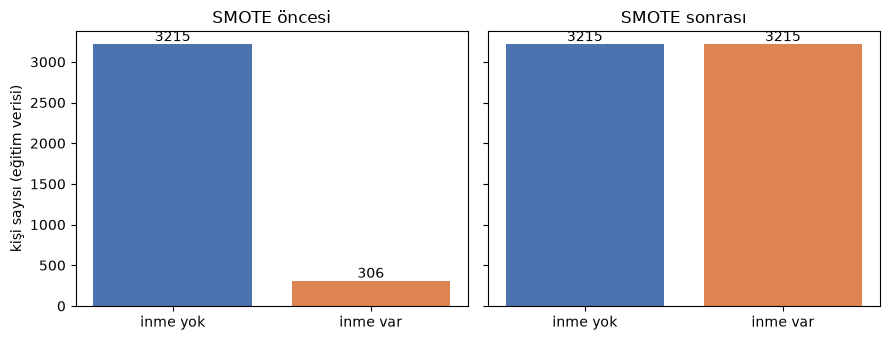

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, (baslik, y) in zip(axes, [("SMOTE öncesi", y_train), ("SMOTE sonrası", y_balanced)]):
    sayilar = y.value_counts().sort_index()
    ax.bar(["inme yok", "inme var"], sayilar.values, color=["#4C72B0", "#DD8452"])
    for i, v in enumerate(sayilar.values):
        ax.text(i, v, str(v), ha="center", va="bottom")
    ax.set_title(baslik)
axes[0].set_ylabel("kişi sayısı (eğitim verisi)")
plt.tight_layout()
plt.savefig("02_smote_oncesi_sonrasi.png", dpi=200)   # rapor için grafik dosyası
plt.show()

> **Not:** Yukarıdaki hücre SMOTE'un etkisini göstermek içindir. Modeller eğitilirken SMOTE elle uygulanmaz; `build_pipeline()` içinde otomatik olarak, cross validation'ın her katında yalnızca eğitim kısmına uygulanır.

## 6. Ekip için kullanım

Her ekip üyesi modelini aşağıdaki şekilde kurar. Kişi 1'in verisi olduğu gibi verilir; feature engineering, encoding, ölçekleme ve dengeleme Pipeline'ın içinde yapılır.

```python
import pandas as pd
from onisleme_pipeline import build_pipeline, veriyi_ayir

X_train, X_test, y_train, y_test = veriyi_ayir(pd.read_csv("train.csv"), pd.read_csv("test.csv"))
pipe = build_pipeline(model, balancing="smote")   # "smote" | "class_weight" | "none"
pipe.fit(X_train, y_train)
```

Colab'da `onisleme_pipeline.py`, `train.csv` ve `test.csv` dosyalarını sol menüden yüklemek yeterlidir.

- **XAI ile birlikte:** Eğitilen `pipe`, Kişi 4'ün `xai_acikla(pipe, X_train, X_test, model_adi=...)` fonksiyonuna doğrudan verilebilir. SHAP grafiklerinde yeni sütun isimleri (`SEX_kadin`, `bp_stage_evre2` vb.) görünür.
- GridSearch'te model parametreleri `model__` ön ekiyle yazılır, ör. `{"model__C": [0.1, 1, 10]}`.
- **Dengeleme:** Varsayılan SMOTE'tur. Ağaç modellerinde (Random Forest, XGBoost) SMOTE'un sentetik örnekleri ezberlenebildiği için `class_weight` da denenmeli ve hangisinin daha iyi olduğu karşılaştırılmalıdır.
- **XGBoost:** `class_weight` parametresi olmadığı için karşılığı kullanılır: `XGBClassifier(scale_pos_weight=scale_pos_weight(y_train))` ve `balancing="none"`.

In [8]:
# Örnek: Pipeline'ın uçtan uca çalıştığının kontrolü (yalnızca eğitim verisiyle)
from sklearn.linear_model import LogisticRegression

pipe = build_pipeline(LogisticRegression(max_iter=3000, random_state=RANDOM_STATE), balancing="smote")
pipe.fit(X_train, y_train)
print("Pipeline adımları:", [ad for ad, _ in pipe.steps])
print("İlk 5 kişinin inme olasılığı:", pipe.predict_proba(X_train.head())[:, 1].round(3))

Pipeline adımları: ['fe', 'encode', 'balance', 'model']
İlk 5 kişinin inme olasılığı: [0.399 0.627 0.156 0.447 0.507]


## 7. Özet (rapor için)

- Framingham verisinin çoğu sütunu zaten sayısal olduğu için encoding sınırlı kaldı: `SEX` 1/2'den 0/1'e çevrildi, `educ` sıralı olduğu için sayısal tutuldu, yeni kategorik özellikler one-hot ile kodlandı.
- Sürekli değişkenler StandardScaler ile standartlaştırıldı (ortalama 0, standart sapma 1).
- Tansiyon, kilo ve eşlik eden hastalık bilgilerinden 5 tıbbi özellik türetildi: nabız basıncı, ortalama arter basıncı, ACC/AHA tansiyon evresi, WHO BMI sınıfı, eşlik eden hastalık sayısı.
- Sınıf dengesizliği SMOTE ile giderildi; SMOTE yalnızca eğitim verisine, Pipeline içinde uygulanır.
- Tüm adımlar `build_pipeline()` fonksiyonunda birleştirildi; ekipteki herkes modelini bu fonksiyonla kurar.